## Importação e Início

In [1]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
plt.style.use('ggplot')

In [2]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
gdown.download(url=url, output=output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=10izoanxrZJnQzkV9UpPI-DX9bt2mYG62
To: /home/gusta/www/projects/datascienceproject/filmes.json


  0%|                                              | 0.00/31.8M [00:00<?, ?B/s]

  2%|▋                                     | 524k/31.8M [00:00<00:13, 2.39MB/s]

 10%|███▋                                 | 3.15M/31.8M [00:00<00:02, 11.3MB/s]

 28%|██████████▎                          | 8.91M/31.8M [00:00<00:00, 26.2MB/s]

 53%|███████████████████▌                 | 16.8M/31.8M [00:00<00:00, 42.4MB/s]

 69%|█████████████████████████▌           | 22.0M/31.8M [00:00<00:00, 44.5MB/s]

 86%|███████████████████████████████▋     | 27.3M/31.8M [00:00<00:00, 46.4MB/s]

100%|█████████████████████████████████████| 31.8M/31.8M [00:00<00:00, 36.4MB/s]

'filmes.json'

In [3]:
df = pd.read_json('filmes.json', orient='records')

### Retirada de Outliers

In [4]:
df = df[
    (df['roi'] < 30000) &
    (df['budget'] > 1000) &
    (df['vote_count'] > 50)
].copy()

### Empresas

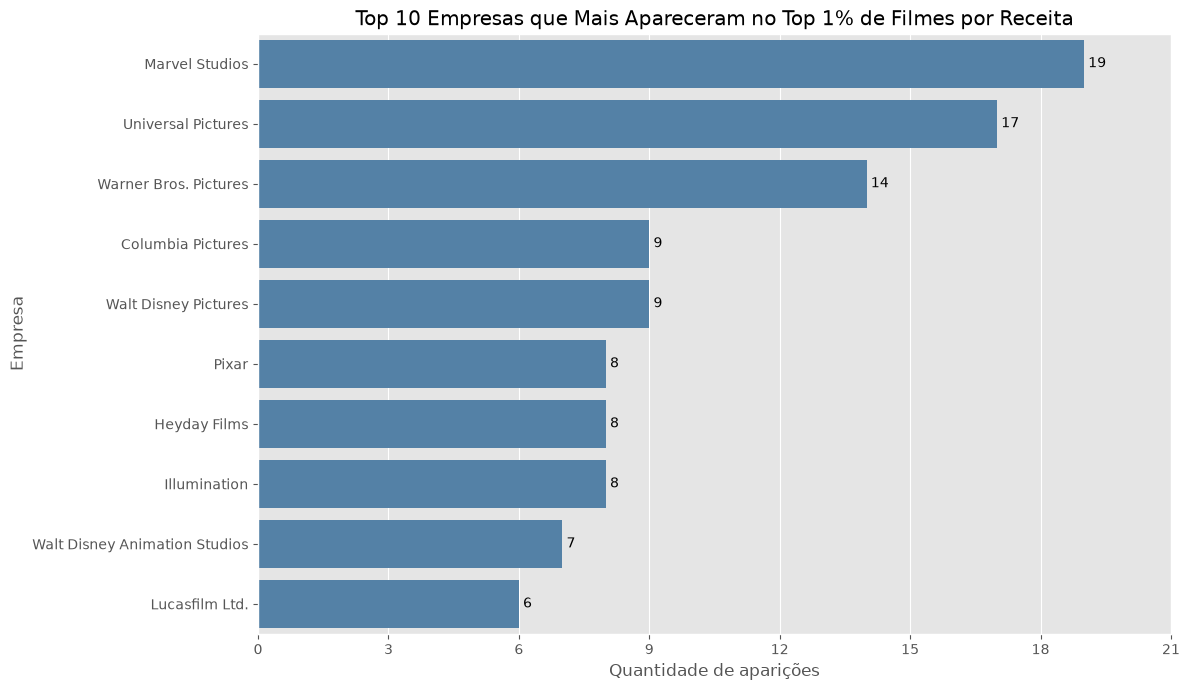

In [5]:
# Seleciona o 1% de filmes com maior receita
quantidade_top_1pct = max(1, int(np.ceil(len(df) * 0.01)))

top_1pct = (
    df.nlargest(quantidade_top_1pct, 'revenue')
      .copy()
)

# Identifica sequências por coleção
top_1pct_com_sequencia = top_1pct.copy()
top_1pct_com_sequencia['eh_sequencia'] = (
    top_1pct_com_sequencia['belongs_to_collection']
    .apply(lambda x: isinstance(x, dict) and bool(x.get('id')))
)

# Conta as produtoras presentes nos filmes do top 1%
companies = (
    top_1pct['production_companies']
    .apply(lambda companies: [
        company.get('name')
        for company in companies
        if isinstance(company, dict) and company.get('name')
    ])
    .explode()
    .dropna()
)

contagem_companies_top_1pct = (
    companies.value_counts()
    .rename_axis('company')
    .reset_index(name='quantidade')
)

top_10_companies = (
    contagem_companies_top_1pct
    .nlargest(10, 'quantidade')
    .sort_values('quantidade', ascending=False)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_companies,
    x='quantidade',
    y='company',
    color='steelblue'
)

ax.set_title('Top 10 Empresas que Mais Apareceram no Top 1% de Filmes por Receita')
ax.set_xlabel('Quantidade de aparições')
ax.set_ylabel('Empresa')
ax.set_xlim(0, top_10_companies['quantidade'].max() + 2)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


Filmes de Sucesso tendem a ser de grandes produtoras.

## Sequências

In [6]:
df['collection'] = df['belongs_to_collection'].apply(
    lambda collection: (
        collection.get('name')
        if isinstance(collection, dict)
        else None
    )
)

In [7]:
df = (
    df.sort_values('release_date', kind='mergesort')
      .reset_index(drop=True)
      .copy()
)

df['eh_sequencia'] = (
    df['collection'].notna()
    & df.groupby('collection', dropna=False).cumcount().gt(0)
)

In [8]:
top_1pct_com_sequencia = (
    top_1pct[['id', 'title', 'revenue']]
    .merge(
        df[['id', 'eh_sequencia']].drop_duplicates('id'),
        on='id',
        how='left'
    )
)

quantidade_top_1pct = len(top_1pct_com_sequencia)
quantidade_sequencias = top_1pct_com_sequencia['eh_sequencia'].fillna(False).sum()

print(f'Quantidade de filmes no top 1%: {quantidade_top_1pct}')
print(f'Quantidade de sequências: {quantidade_sequencias}')
porcentagem_sequencias = quantidade_sequencias / quantidade_top_1pct * 100

print(f'Porcentagem de sequências no top 1%: {porcentagem_sequencias:.2f}%')

Quantidade de filmes no top 1%: 104
Quantidade de sequências: 70
Porcentagem de sequências no top 1%: 67.31%


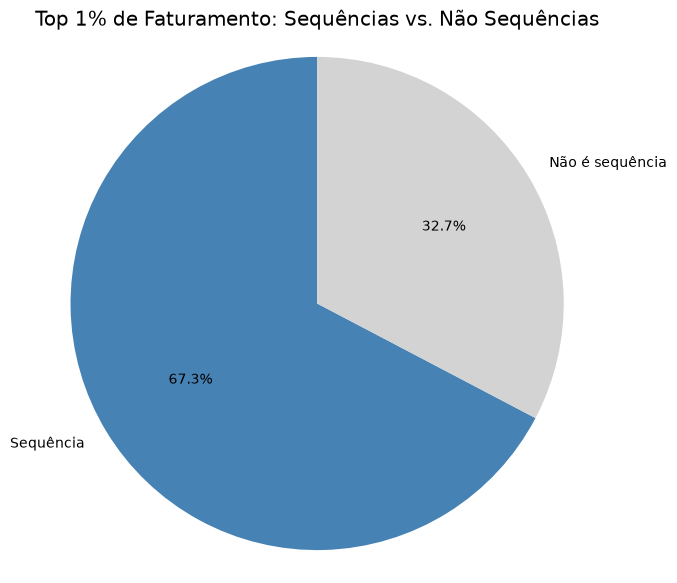

In [9]:
contagem_sequencias = (
    top_1pct_com_sequencia['eh_sequencia']
    .map({True: 'Sequência', False: 'Não é sequência'})
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(
    contagem_sequencias.values,
    labels=contagem_sequencias.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['steelblue', 'lightgray']
)

plt.title('Top 1% de Faturamento: Sequências vs. Não Sequências')
plt.axis('equal')
plt.show()

Filmes de Sucesso de Bilheteria tendem a ser Sequências

## Orçamento

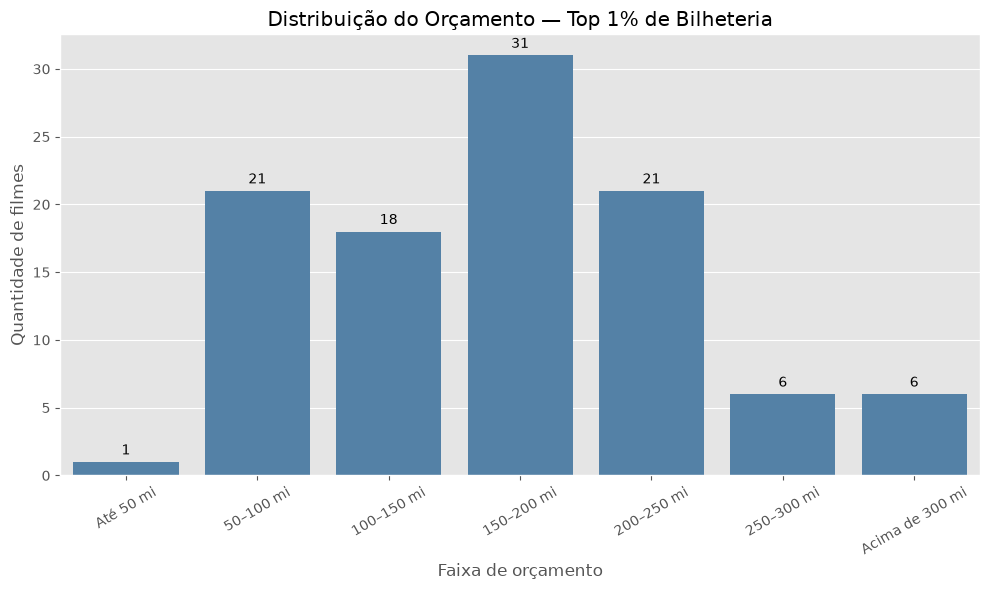

In [10]:
# Agrupa o orçamento do Top 1% em faixas de US$ milhões
faixas_orcamento = [0, 50, 100, 150, 200, 250, 300, np.inf]
rotulos_orcamento = [
    'Até 50 mi',
    '50–100 mi',
    '100–150 mi',
    '150–200 mi',
    '200–250 mi',
    '250–300 mi',
    'Acima de 300 mi'
]

orcamento_agrupado = (
    pd.cut(
        top_1pct['budget'] / 1_000_000,
        bins=faixas_orcamento,
        labels=rotulos_orcamento,
        include_lowest=True
    )
    .value_counts()
    .reindex(rotulos_orcamento, fill_value=0)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=orcamento_agrupado.index,
    y=orcamento_agrupado.values,
    color='steelblue'
)

ax.set_title('Distribuição do Orçamento — Top 1% de Bilheteria')
ax.set_xlabel('Faixa de orçamento')
ax.set_ylabel('Quantidade de filmes')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [11]:
mediana_budget_top_1pct = top_1pct['budget'].median()

print(f"Mediana do orçamento do Top 1%: US$ {mediana_budget_top_1pct:,.2f}")
mediana_budget = df['budget'].median()

print(f"Mediana do orçamento: US$ {mediana_budget:,.2f}")

Mediana do orçamento do Top 1%: US$ 181,500,000.00
Mediana do orçamento: US$ 12,500,000.00


Portanto, um maior orçamento é um fator para o sucesso da Bilheteria.

## Mês e dia da Semana

In [12]:
# Conversão das datas e criação das variáveis de sazonalidade
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_month'] = df['release_date'].dt.month
df['release_day_name'] = df['release_date'].dt.day_name()

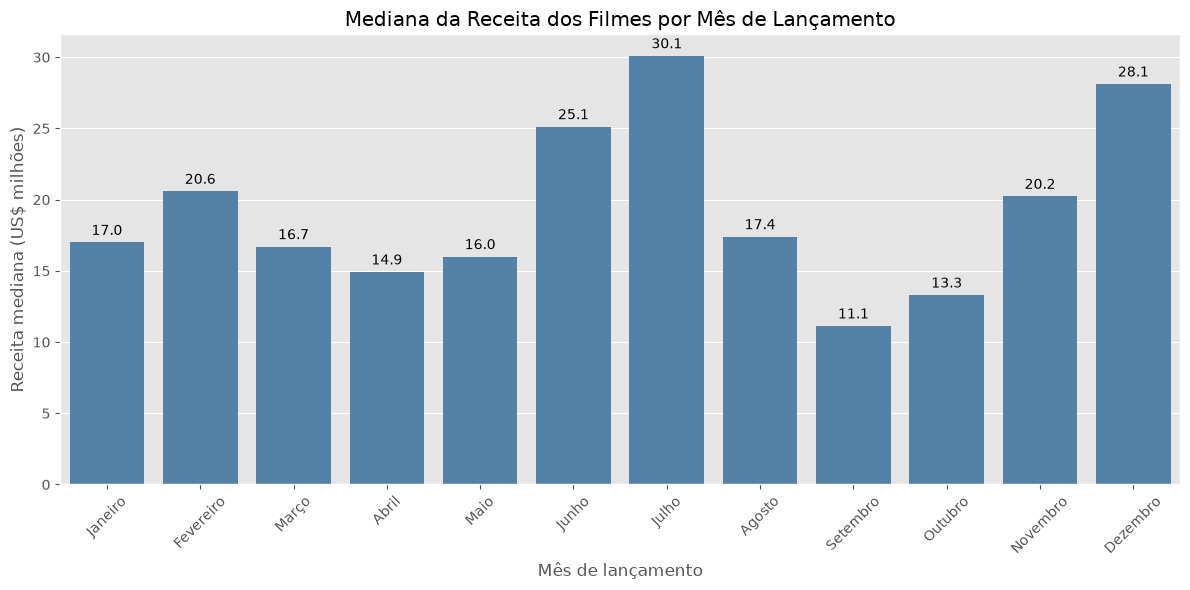

In [13]:
meses = [
    'Janeiro', 'Fevereiro', 'Março', 'Abril',
    'Maio', 'Junho', 'Julho', 'Agosto',
    'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]

receita_mediana_por_mes = (
    df.dropna(subset=['release_month', 'revenue'])
      .groupby('release_month')['revenue']
      .median()
      .reindex(range(1, 13))
      .div(1_000_000)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=meses,
    y=receita_mediana_por_mes.values,
    color='steelblue'
)

ax.set_title('Mediana da Receita dos Filmes por Mês de Lançamento')
ax.set_xlabel('Mês de lançamento')
ax.set_ylabel('Receita mediana (US$ milhões)')
ax.tick_params(axis='x', rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

O Mês de Lançamento impacta no sucesso financeiro do Filme

### Receita por dia da semana

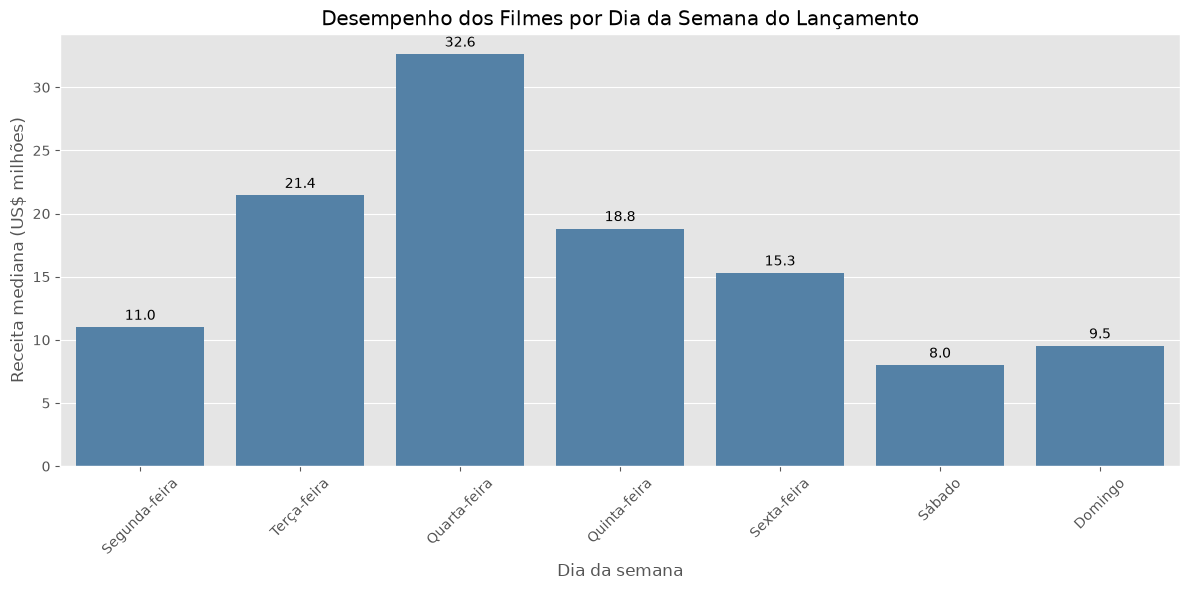

In [14]:
dias_pt = {
    'Monday': 'Segunda-feira',
    'Tuesday': 'Terça-feira',
    'Wednesday': 'Quarta-feira',
    'Thursday': 'Quinta-feira',
    'Friday': 'Sexta-feira',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_performance = (
    df.dropna(subset=['release_day_name', 'revenue'])
      .groupby('release_day_name', as_index=False)['revenue']
      .median()
      .rename(columns={'revenue': 'receita_mediana_milhoes'})
)

day_performance['receita_mediana_milhoes'] /= 1_000_000
day_performance['dia_semana'] = day_performance['release_day_name'].map(dias_pt)

ordem_pt = [dias_pt[dia] for dia in day_order]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=day_performance,
    x='dia_semana',
    y='receita_mediana_milhoes',
    order=ordem_pt,
    color='steelblue'
)

ax.set_title('Desempenho dos Filmes por Dia da Semana do Lançamento')
ax.set_xlabel('Dia da semana')
ax.set_ylabel('Receita mediana (US$ milhões)')
ax.tick_params(axis='x', rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()


Conclusão: O dia da semana impacta no sucesso financeiro do Filme

## Gênero

### Gêneros Predominantes no Top 1% de Bilheteria

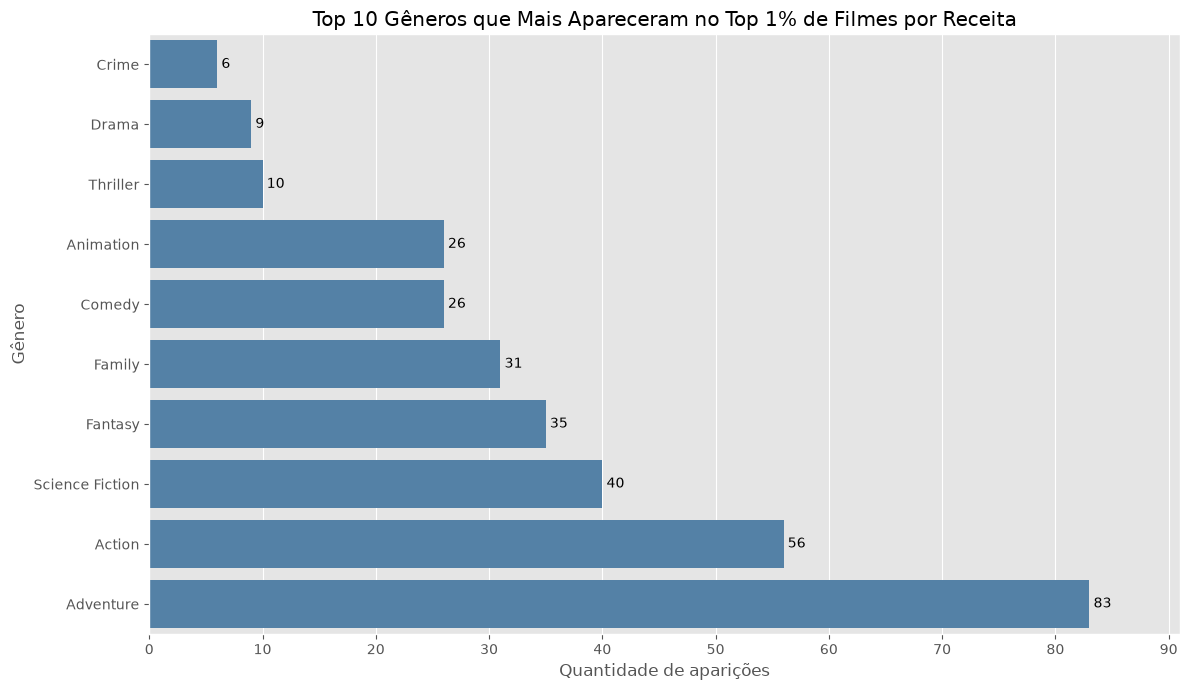

In [15]:
# Extrai os gêneros presentes nos filmes do Top 1% de bilheteria
top_1pct_genres = (
    top_1pct['genres']
    .apply(lambda genres: [
        genre.get('name')
        for genre in genres
        if isinstance(genre, dict) and genre.get('name')
    ])
    .explode()
    .dropna()
)

contagem_genres_top_1pct = (
    top_1pct_genres.value_counts()
    .rename_axis('genre')
    .reset_index(name='quantidade')
)

top_10_genres = (
    contagem_genres_top_1pct
    .nlargest(10, 'quantidade')
    .sort_values('quantidade', ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_genres,
    x='quantidade',
    y='genre',
    color='steelblue'
)

ax.set_title('Top 10 Gêneros que Mais Apareceram no Top 1% de Filmes por Receita')
ax.set_xlabel('Quantidade de aparições')
ax.set_ylabel('Gênero')
ax.set_xlim(0, top_10_genres['quantidade'].max() + 8)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


Filmes de Maior Sucesso pertencem predominantemente aos gêneros de **Aventura** e **Ação** (presentes em mais de 80% e 54% dos filmes do Top 1%, respectivamente).

### Lucro Mediano por Gênero (Maior Probabilidade de Lucro)

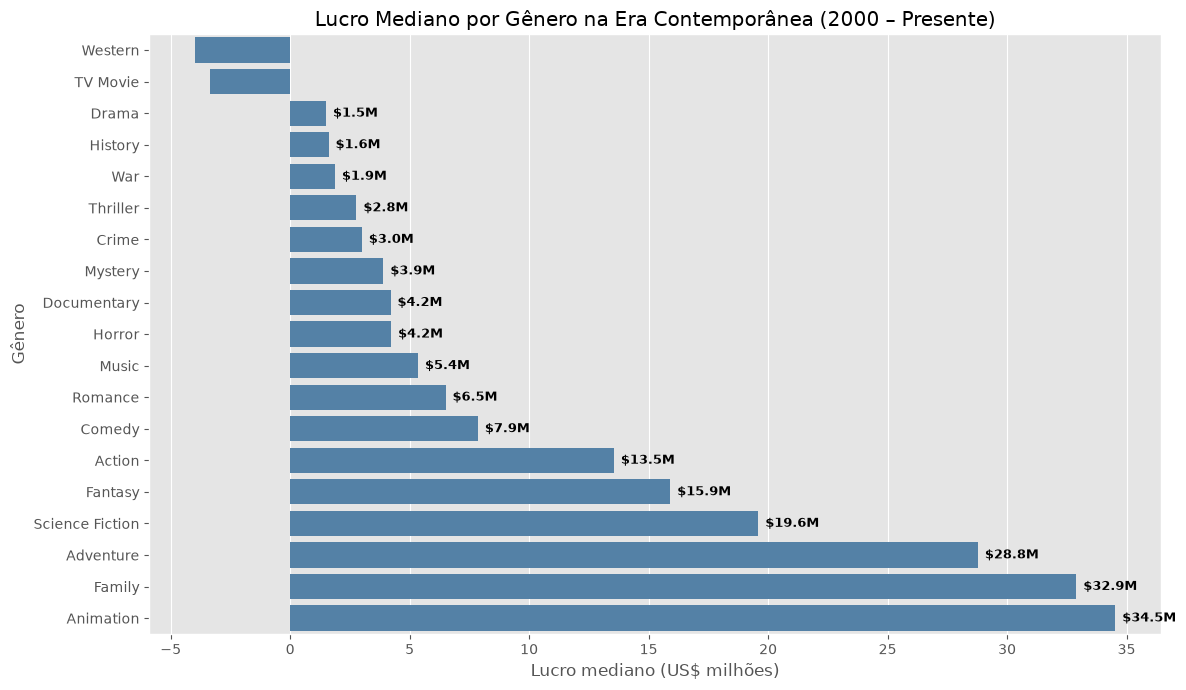

In [16]:
# Descompacta a coluna de gêneros do dataset completo
df_genres = df.explode('genres').reset_index(drop=True)
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)
df_genres = df_genres.dropna(subset=['genre', 'release_date']).reset_index(drop=True)

# Cria ano e década caso ainda não existam
df_genres['year'] = df_genres['release_date'].dt.year
df_genres['decada'] = (df_genres['year'] // 10) * 10

# Lucro mediano por gênero na era contemporânea (2000 em diante)
lucro_mediano_generos = (
    df_genres[df_genres['decada'] >= 2000]
    .groupby('genre')['profit']
    .median()
    .div(1_000_000)
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=lucro_mediano_generos.values,
    y=lucro_mediano_generos.index,
    color='steelblue'
)

ax.set_title('Lucro Mediano por Gênero na Era Contemporânea (2000 – Presente)')
ax.set_xlabel('Lucro mediano (US$ milhões)')
ax.set_ylabel('Gênero')

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'${width:.1f}M',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(5, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9.5,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()


Para maximizar a probabilidade de lucro e mitigar risco, filmes de **Animação**, **Família** e **Aventura** apresentam as maiores medianas de rentabilidade da indústria (acima de US$ 28 milhões por título), superando em mais de 3x gêneros como Comédia e Drama.

### Eficiência por Gênero: Volume de Lançamentos vs. Lucro Gerado

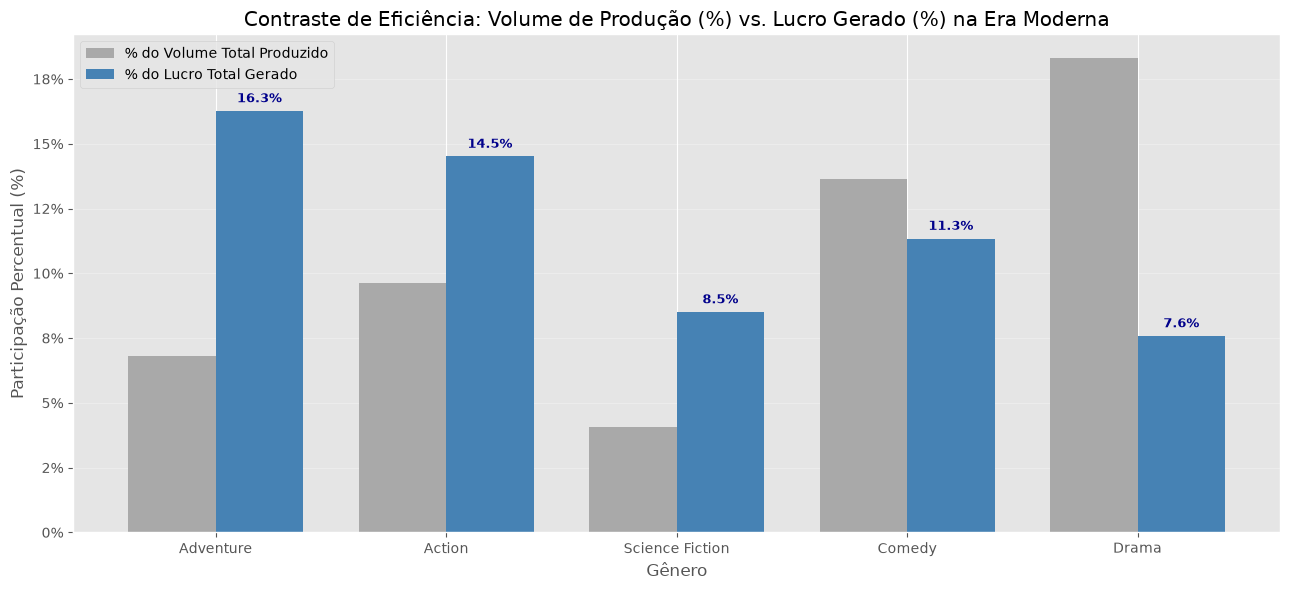

In [17]:
# Compara a fatia de mercado de produção vs. fatia de lucro gerado nos anos 2000+
generos_analise = ['Adventure', 'Action', 'Science Fiction', 'Comedy', 'Drama']

dados_contraste = (
    df_genres[df_genres['decada'].between(2000, 2026) & df_genres['genre'].isin(generos_analise)]
    .groupby('genre')
    .agg(
        total_filmes=('id', 'count'),
        lucro_total=('profit', 'sum')
    )
    .loc[generos_analise]
)

total_geral_filmes = df_genres[df_genres['decada'].between(2000, 2026)]['id'].count()
total_geral_lucro = df_genres[df_genres['decada'].between(2000, 2026)]['profit'].sum()

pct_producao = (dados_contraste['total_filmes'] / total_geral_filmes) * 100
pct_lucro = (dados_contraste['lucro_total'] / total_geral_lucro) * 100

plt.figure(figsize=(13, 6))

x = np.arange(len(generos_analise))
largura = 0.38

b1 = plt.bar(
    x - largura/2,
    pct_producao,
    largura,
    label='% do Volume Total Produzido',
    color='darkgray'
)

b2 = plt.bar(
    x + largura/2,
    pct_lucro,
    largura,
    label='% do Lucro Total Gerado',
    color='steelblue'
)

for barra in b2:
    altura = barra.get_height()
    plt.annotate(
        f'{altura:.1f}%',
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9.5,
        fontweight='bold',
        color='darkblue'
    )

plt.title('Contraste de Eficiência: Volume de Produção (%) vs. Lucro Gerado (%) na Era Moderna')
plt.xlabel('Gênero')
plt.ylabel('Participação Percentual (%)')
plt.xticks(x, generos_analise)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:.0f}%')
)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Aventura** e **Ficção Científica** são os gêneros mais eficientes do cinema: concentram uma fatia de lucro proporcionalmente muito superior ao seu volume de lançamentos (Aventura faz ~20% do lucro com apenas ~7% dos lançamentos).

### Transformação Histórica: Domínio dos Filmes de Espetáculo (Aventura, Ação e Sci-Fi)

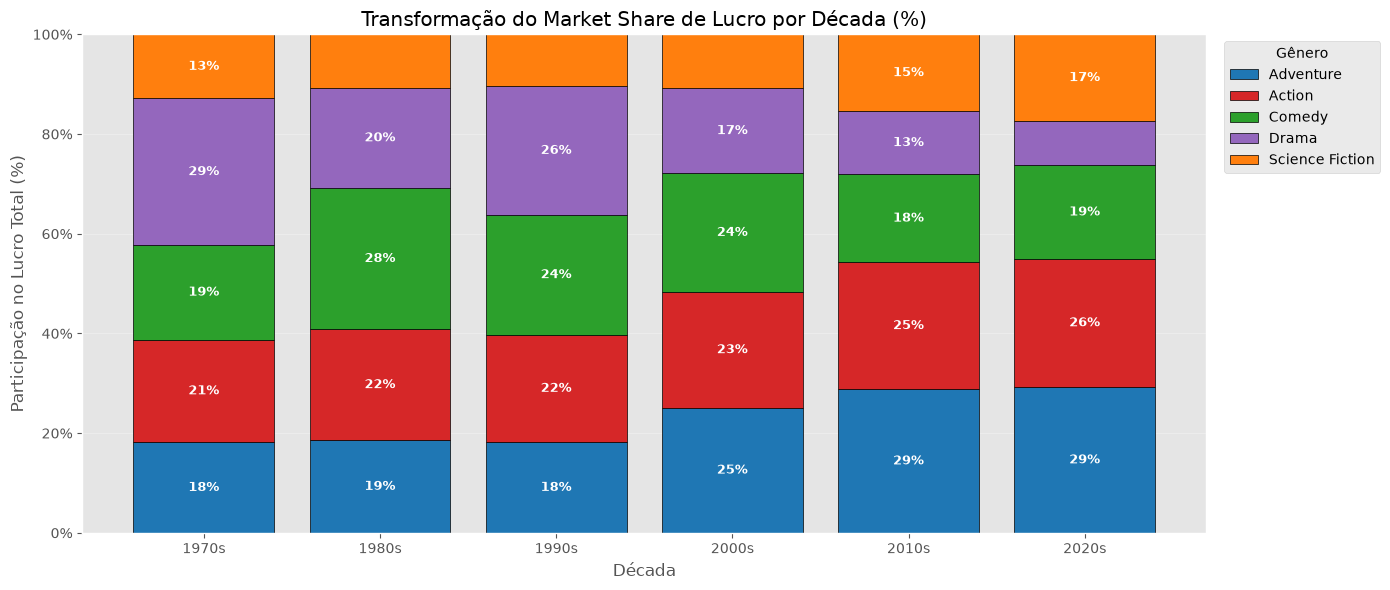

In [18]:
principais_generos = ['Adventure', 'Action', 'Comedy', 'Drama', 'Science Fiction']

cores_generos = {
    'Adventure': '#1f77b4',
    'Action': '#d62728',
    'Comedy': '#2ca02c',
    'Drama': '#9467bd',
    'Science Fiction': '#ff7f0e'
}

pivot_share = (
    df_genres[df_genres['genre'].isin(principais_generos) & (df_genres['decada'] >= 1970)]
    .groupby(['decada', 'genre'])['profit']
    .sum()
    .unstack()
)

pivot_share_pct = pivot_share[principais_generos].div(pivot_share[principais_generos].sum(axis=1), axis=0) * 100

plt.figure(figsize=(14, 6))

bottom = np.zeros(len(pivot_share_pct))
x_labels = [f"{int(d)}s" for d in pivot_share_pct.index]

for genero in principais_generos:
    valores = pivot_share_pct[genero].values
    plt.bar(
        x_labels,
        valores,
        bottom=bottom,
        label=genero,
        color=cores_generos[genero],
        edgecolor='black',
        linewidth=0.5
    )
    for idx, v in enumerate(valores):
        if v >= 12:
            plt.text(
                idx,
                bottom[idx] + v / 2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                color='white',
                fontweight='bold',
                fontsize=9.5
            )
    bottom += valores

plt.title('Transformação do Market Share de Lucro por Década (%)')
plt.xlabel('Década')
plt.ylabel('Participação no Lucro Total (%)')
plt.ylim(0, 100)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:.0f}%')
)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Gênero', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()


Conclusão: O mercado cinematográfico moderno migrou decisivamente para filmes de espetáculo visual: hoje, mais de **70% de todo o lucro da indústria** é capturado por **Aventura, Ação e Ficção Científica**.

### O Sucesso ao Longo do Tempo (Ajustado pela Inflação)

In [19]:
# Série histórica anual do CPI-U dos EUA para ajuste de inflação (base 2024 USD)
cpi_historico = {
    1913: 9.9, 1914: 10.0, 1915: 10.1, 1916: 10.9, 1917: 12.8, 1918: 15.1, 1919: 17.3,
    1920: 20.0, 1921: 17.9, 1922: 16.8, 1923: 17.1, 1924: 17.1, 1925: 17.5, 1926: 17.7, 1927: 17.4, 1928: 17.1, 1929: 17.1,
    1930: 16.7, 1931: 15.2, 1932: 13.7, 1933: 13.0, 1934: 13.4, 1935: 13.7, 1936: 13.9, 1937: 14.4, 1938: 14.1, 1939: 13.9,
    1940: 14.0, 1941: 14.7, 1942: 16.3, 1943: 17.3, 1944: 17.6, 1945: 18.0, 1946: 19.5, 1947: 22.3, 1948: 24.1, 1949: 23.8,
    1950: 24.1, 1951: 26.0, 1952: 26.5, 1953: 26.7, 1954: 26.9, 1955: 26.8, 1956: 27.2, 1957: 28.1, 1958: 28.9, 1959: 29.1,
    1960: 29.6, 1961: 29.9, 1962: 30.2, 1963: 30.6, 1964: 31.0, 1965: 31.5, 1966: 32.4, 1967: 33.4, 1968: 34.8, 1969: 36.7,
    1970: 38.8, 1971: 40.5, 1972: 41.8, 1973: 44.4, 1974: 49.3, 1975: 53.8, 1976: 56.9, 1977: 60.6, 1978: 65.2, 1979: 72.6,
    1980: 82.4, 1981: 90.9, 1982: 96.5, 1983: 99.6, 1984: 103.9, 1985: 107.6, 1986: 109.6, 1987: 113.6, 1988: 118.3, 1989: 124.0,
    1990: 130.7, 1991: 136.2, 1992: 140.3, 1993: 144.5, 1994: 148.2, 1995: 152.4, 1996: 156.9, 1997: 160.5, 1998: 163.0, 1999: 166.6,
    2000: 172.2, 2001: 177.1, 2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3, 2006: 201.6, 2007: 207.3, 2008: 215.3, 2009: 214.5,
    2010: 218.1, 2011: 224.9, 2012: 229.6, 2013: 233.0, 2014: 236.7, 2015: 237.0, 2016: 240.0, 2017: 245.1, 2018: 251.1, 2019: 255.7,
    2020: 258.8, 2021: 271.0, 2022: 292.7, 2023: 304.7, 2024: 314.0, 2025: 320.0, 2026: 325.0
}

df['year'] = df['release_date'].dt.year
cpi_base = 314.0
df['fator_inflacao'] = cpi_base / df['year'].map(cpi_historico).fillna(cpi_base)
df['profit_adj'] = (df['revenue'] - df['budget']) * df['fator_inflacao']

top_10_historico = df.sort_values('profit_adj', ascending=False).head(10)

tabela_historica = pd.DataFrame({
    'Título': top_10_historico['title'],
    'Ano': top_10_historico['year'],
    'Lucro Real Ajustado ($B)': (top_10_historico['profit_adj'] / 1e9).round(2),
    'Lucro Nominal ($B)': (top_10_historico['profit'] / 1e9).round(2),
    'Multiplicador Inflação': top_10_historico['fator_inflacao'].round(1)
})

tabela_historica.reset_index(drop=True)


,Título,Ano,Lucro Real Ajustado ($B),Lucro Nominal ($B),Multiplicador Inflação
0,Gone with the Wind,1939,9.00,0.40,22.6
1,Bambi,1942,5.14,0.27,19.3
2,Snow White and the Seven Dwarfs,1938,4.09,0.18,22.3
3,Titanic,1997,4.04,2.06,2.0
4,Star Wars,1977,3.96,0.76,5.2
5,Avatar,2009,3.93,2.69,1.5
6,Pinocchio,1940,3.62,0.16,22.4
7,The Jungle Book,1967,3.52,0.37,9.4
8,Cinderella,1950,3.40,0.26,13.0
9,Avengers: Endgame,2019,3.17,2.58,1.2


Conclusão: Mesmo corrigindo pela inflação histórica, os maiores sucessos comerciais de todos os tempos são invariavelmente grandes produções épicas e de aventura.